In [35]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix)
import statistics

In [36]:
df = pd.read_csv("New_York_Dataset.csv")
york = df

In [37]:
df.head()

,county,neighborhood_label,median_hh_income_2014,median_hh_income_2024,pct_bachelors_plus_2014,pct_bachelors_plus_2024,pct_owner_occupied_2014,pct_owner_occupied_2024
0,York County,Lincoln Estates area,41786.0,54618.0,14.25,23.26,56.34,71.38
1,York County,Seven Oaks area,47177.0,82702.0,45.76,45.51,42.72,53.81
2,York County,Prestwick / Nations Ford,72481.0,90931.0,35.82,52.60,85.67,74.95
3,York County,North Rock Hill area,44103.0,57860.0,24.55,28.92,51.33,61.52
4,York County,York County,86938.0,125162.0,44.41,48.15,86.75,93.66


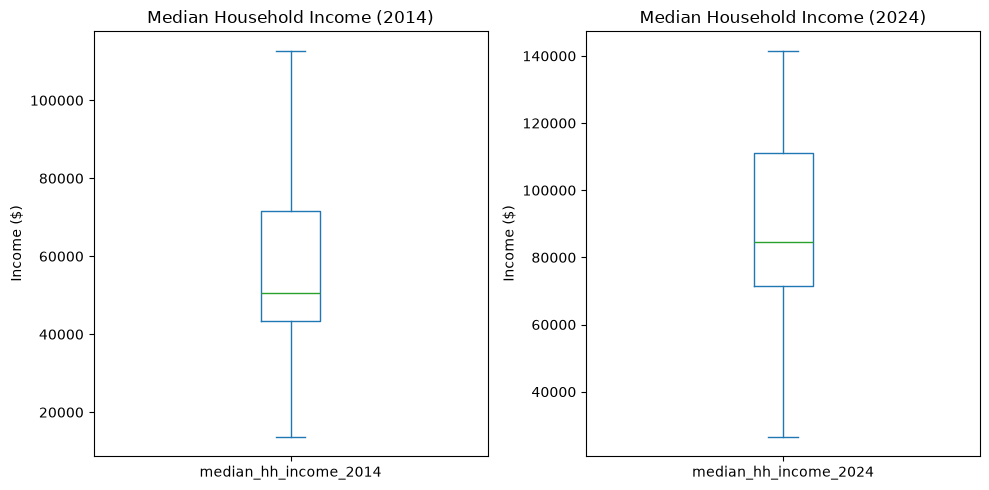

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

york["median_hh_income_2014"].dropna().plot.box(ax=axes[0])
axes[0].set_title("Median Household Income (2014)")
axes[0].set_ylabel("Income ($)")

york["median_hh_income_2024"].dropna().plot.box(ax=axes[1])
axes[1].set_title("Median Household Income (2024)")
axes[1].set_ylabel("Income ($)")

plt.tight_layout()
plt.show()

In [39]:
statistics.median(df["median_hh_income_2014"].dropna())

50580.5

In [40]:
statistics.median(df["median_hh_income_2024"].dropna())

84651.5

In [41]:
neighborhood_counts = york["neighborhood_label"].value_counts()
neighborhood_counts[neighborhood_counts > 1]

neighborhood_label
North Rock Hill area                9
York County                         7
Lincoln Estates area                4
Seven Oaks area                     4
West Rock Hill area                 3
South Rock Hill area                2
West Rock Hill / North Rock Hill    2
The Sanctuary area                  2
South Rock Hill / West Rock Hill    2
Name: count, dtype: int64

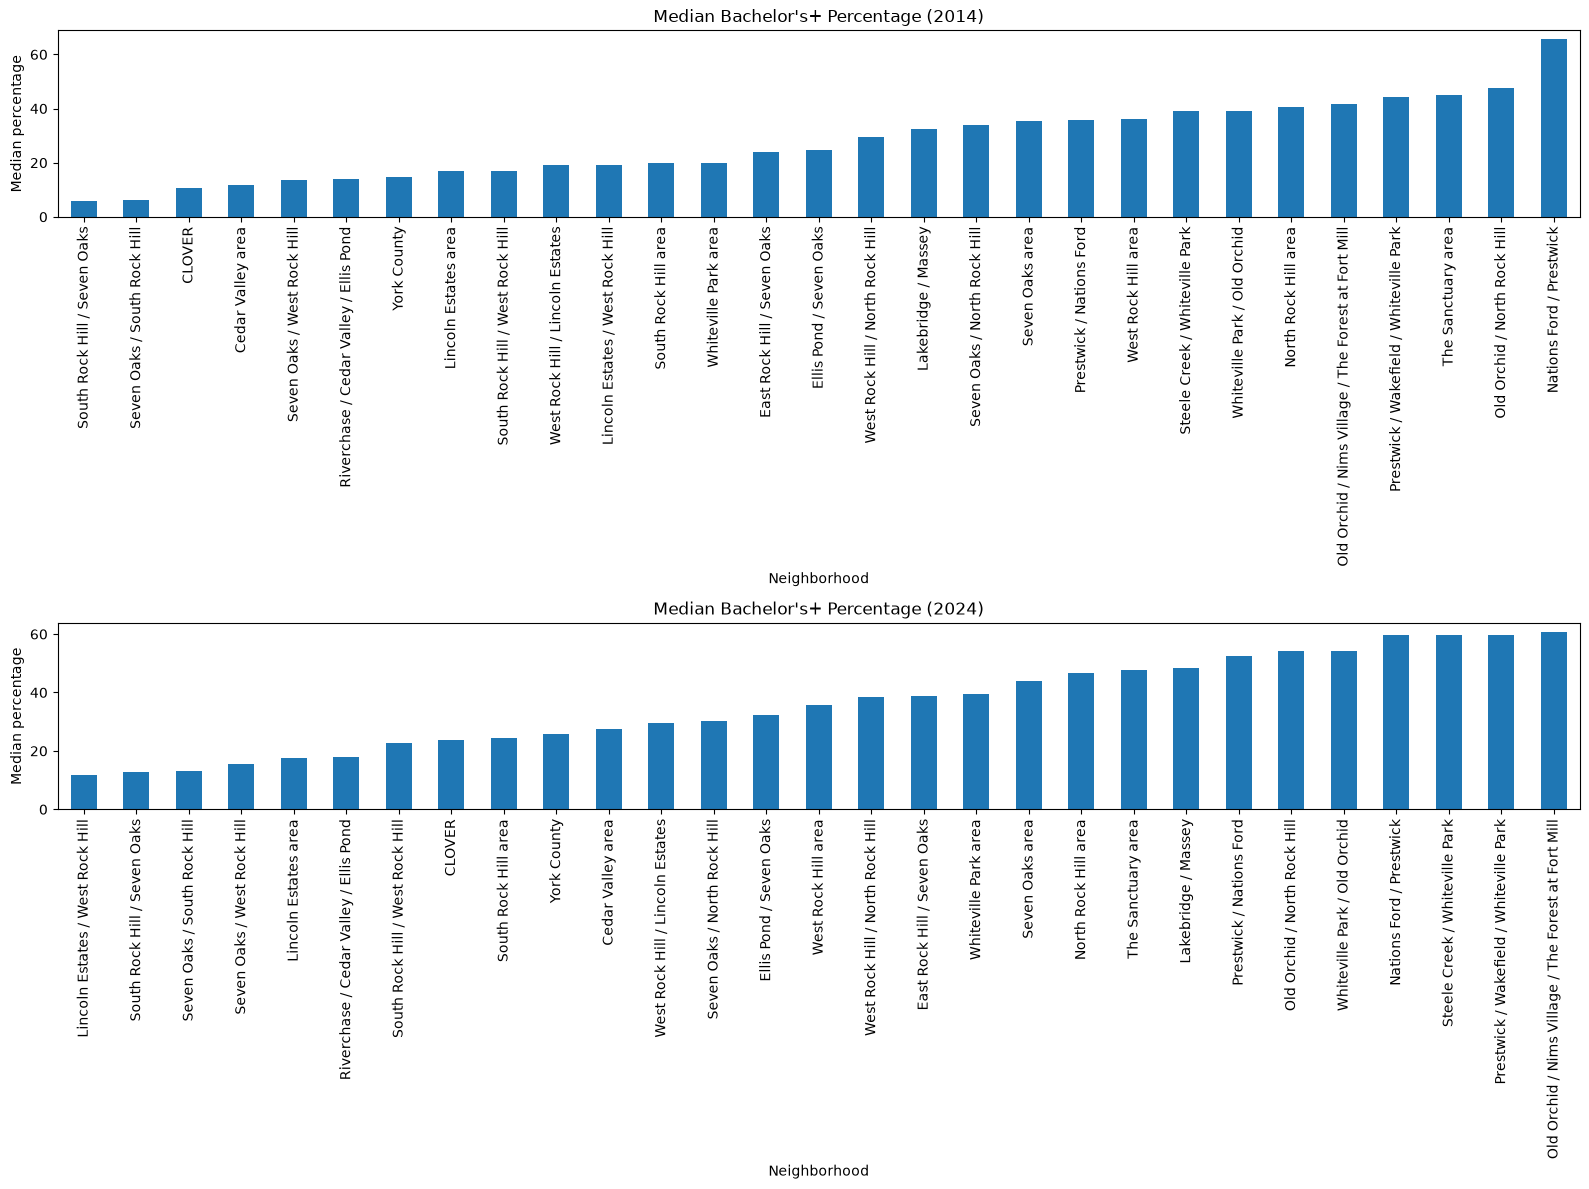

In [42]:
columns = ["pct_bachelors_plus_2014", "pct_bachelors_plus_2024"]
titles = ["Median Bachelor's+ Percentage (2014)", "Median Bachelor's+ Percentage (2024)"]

fig, axes = plt.subplots(2, 1, figsize=(16, 12))

for ax, column, title in zip(axes, columns, titles):
    medians = (
        york.groupby("neighborhood_label")[column]
        .median()
        .dropna()
        .sort_values()
    )
    medians.plot.bar(ax=ax)
    ax.set_title(title)
    ax.set_xlabel("Neighborhood")
    ax.set_ylabel("Median percentage")
    ax.tick_params(axis="x", labelrotation=90)

plt.tight_layout()
plt.show()

In [43]:
model1 = smf.ols("median_hh_income_2014 ~ pct_bachelors_plus_2014 + pct_owner_occupied_2014", data=df).fit()
model1.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                              OLS Regression Results                             
=================================================================================
Dep. Variable:     median_hh_income_2014   R-squared:                       0.864
Model:                               OLS   Adj. R-squared:                  0.858
Method:                    Least Squares   F-statistic:                     161.4
Date:                   Thu, 19 Nov 2026   Prob (F-statistic):           8.68e-23
Time:                           16:01:10   Log-Likelihood:                -560.22
No. Observations:                     54   AIC:                             1126.
Df Residuals:                         51   BIC:                             1132.
Df Model:                              2                                         
Covariance Type:               nonrobust                                         
===========================================================================================
                              coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------
Intercept               -1.052e+04   4743.017     -2.217      0.031      -2e+04    -994.920
pct_bachelors_plus_2014  1060.6236     76.695     13.829      0.000     906.653    1214.595
pct_owner_occupied_2014   525.6404     65.241      8.057      0.000     394.664     656.617
==============================================================================
Omnibus:                        1.446   Durbin-Watson:                   1.541
Prob(Omnibus):                  0.485   Jarque-Bera (JB):                0.704
Skew:                          -0.155   Prob(JB):                        0.703
Kurtosis:                       3.465   Cond. No.                         341.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

<Axes: xlabel='pct_bachelors_plus_2014', ylabel='median_hh_income_2014'>

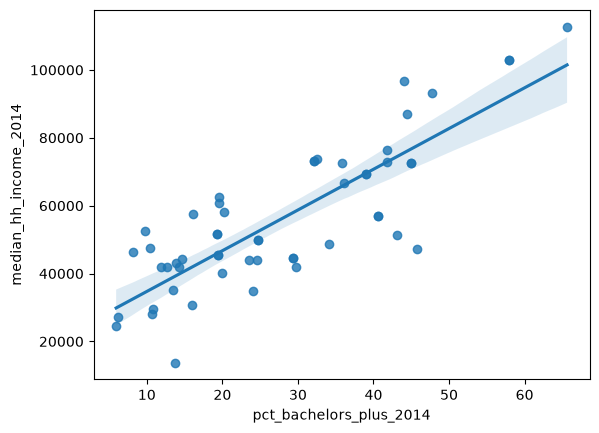

In [44]:
sns.regplot(x="pct_bachelors_plus_2014", y="median_hh_income_2014" , data=df)

In [45]:
model2 = smf.ols("median_hh_income_2024 ~ pct_bachelors_plus_2024 + pct_owner_occupied_2024", data=df).fit()
model2.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                              OLS Regression Results                             
=================================================================================
Dep. Variable:     median_hh_income_2024   R-squared:                       0.844
Model:                               OLS   Adj. R-squared:                  0.838
Method:                    Least Squares   F-statistic:                     137.6
Date:                   Thu, 19 Nov 2026   Prob (F-statistic):           2.81e-21
Time:                           16:01:10   Log-Likelihood:                -580.40
No. Observations:                     54   AIC:                             1167.
Df Residuals:                         51   BIC:                             1173.
Df Model:                              2                                         
Covariance Type:               nonrobust                                         
===========================================================================================
                              coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------
Intercept               -1.543e+04   7299.462     -2.113      0.039   -3.01e+04    -772.888
pct_bachelors_plus_2024  1346.7070    102.354     13.157      0.000    1141.223    1552.191
pct_owner_occupied_2024   746.6204     87.943      8.490      0.000     570.067     923.174
==============================================================================
Omnibus:                        0.434   Durbin-Watson:                   2.190
Prob(Omnibus):                  0.805   Jarque-Bera (JB):                0.169
Skew:                           0.135   Prob(JB):                        0.919
Kurtosis:                       3.044   Cond. No.                         392.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

<Axes: xlabel='pct_bachelors_plus_2024', ylabel='median_hh_income_2024'>

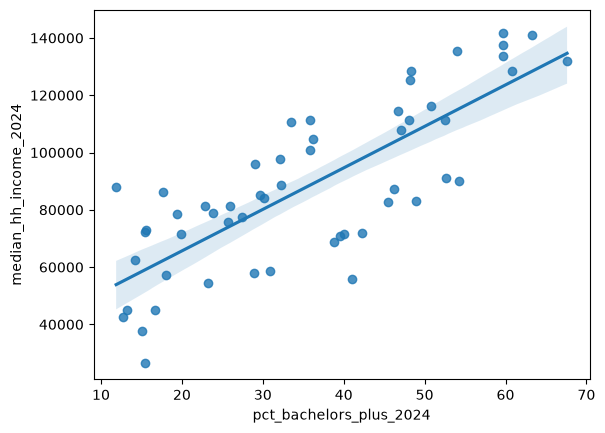

In [46]:
sns.regplot(x="pct_bachelors_plus_2024", y="median_hh_income_2024" , data=df)

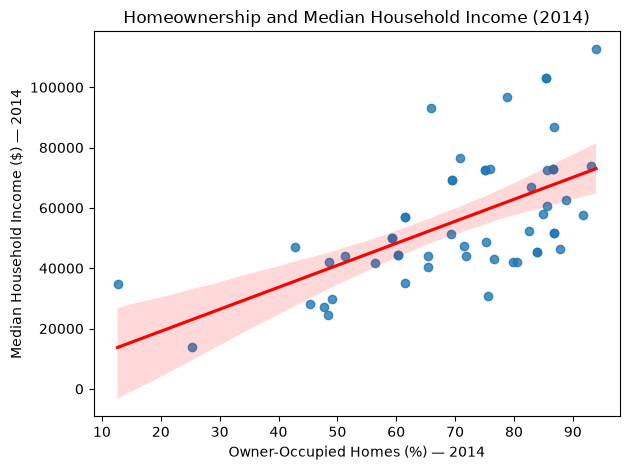

In [47]:
sns.regplot(
    data=df,
    x="pct_owner_occupied_2014",
    y="median_hh_income_2014",
    line_kws={"color": "red"}
)

plt.xlabel("Owner-Occupied Homes (%) — 2014")
plt.ylabel("Median Household Income ($) — 2014")
plt.title("Homeownership and Median Household Income (2014)")
plt.tight_layout()
plt.show()

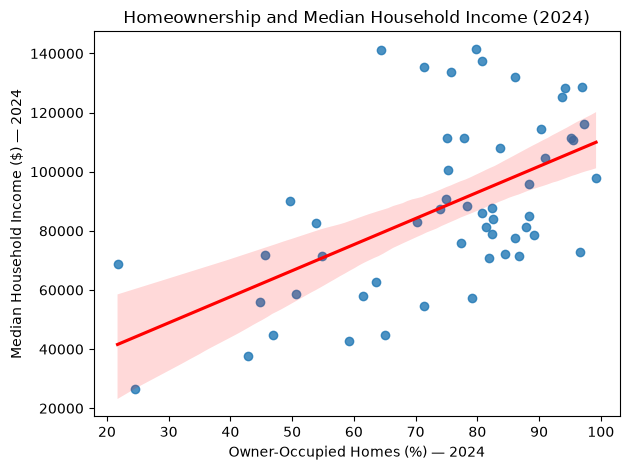

In [48]:
sns.regplot(
    data=df,
    x="pct_owner_occupied_2024",
    y="median_hh_income_2024",
    line_kws={"color": "red"}
)

plt.xlabel("Owner-Occupied Homes (%) — 2024")
plt.ylabel("Median Household Income ($) — 2024")
plt.title("Homeownership and Median Household Income (2024)")
plt.tight_layout()
plt.show()

In [49]:
plot_data = york[[x_col, y_col]].dropna().copy()
plot_data["interval"] = pd.cut(plot_data[x_col], bins=8)

summary = plot_data.groupby("interval", observed=False)[y_col].agg(
    median_income="median",
    neighborhood_count="count"
)

display(summary)

ax = summary["median_income"].plot.bar(figsize=(10, 5))
ax.set_title("Median Household Income by Bachelor's+ Percentage (2014)")
ax.set_xlabel("Bachelor's+ percentage interval (2014)")
ax.set_ylabel("Median household income ($)")
ax.tick_params(axis="x", labelrotation=45)
plt.tight_layout()
plt.show()

NameError: name 'x_col' is not defined

,median_income,neighborhood_count
owner_interval,,
"(12.569, 22.812]",34737.0,1
"(22.812, 32.975]",13735.0,1
"(32.975, 43.137]",47177.0,1
"(43.137, 53.3]",28903.0,6
"(53.3, 63.462]",47179.0,8
"(63.462, 73.625]",51250.0,9
"(73.625, 83.788]",52448.0,11
"(83.788, 93.95]",62459.0,17


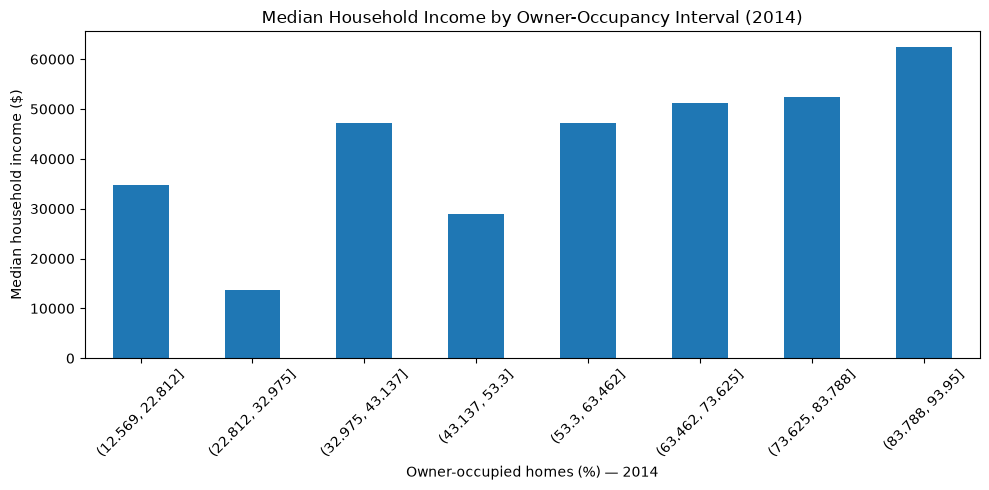

In [ ]:
owner_col = "pct_owner_occupied_2014"
income_col = "median_hh_income_2014"

plot_data = york[[owner_col, income_col]].dropna().copy()
plot_data["owner_interval"] = pd.cut(plot_data[owner_col], bins=8)

income_by_interval = plot_data.groupby("owner_interval", observed=True)[income_col].agg(
    median_income="median",
    neighborhood_count="count"
)

display(income_by_interval)

ax = income_by_interval["median_income"].plot.bar(figsize=(10, 5))
ax.set_title("Median Household Income by Owner-Occupancy Interval (2014)")
ax.set_xlabel("Owner-occupied homes (%) — 2014")
ax.set_ylabel("Median household income ($)")
ax.tick_params(axis="x", labelrotation=45)
plt.tight_layout()
plt.show()

,median_income,neighborhood_count
interval,,
"(11.814, 18.838]",57286.0,11
"(18.838, 25.805]",77234.0,6
"(25.805, 32.772]",84141.0,9
"(32.772, 39.74]",102770.0,6
"(39.74, 46.707]",71991.0,5
"(46.707, 53.675]",111356.0,9
"(53.675, 60.642]",135299.0,5
"(60.642, 67.61]",131974.0,3


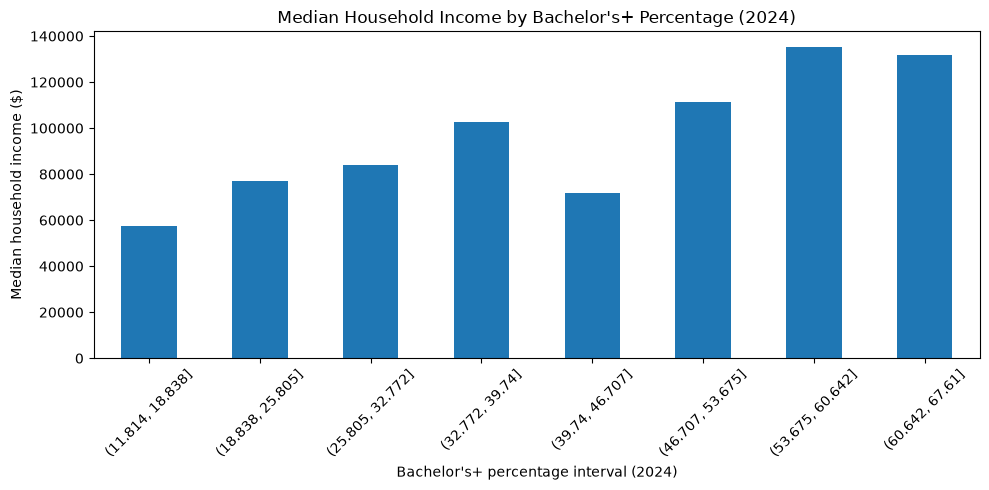

In [ ]:
x_2024 = "pct_bachelors_plus_2024"
y_2024 = "median_hh_income_2024"

plot_data_2024 = york[[x_2024, y_2024]].dropna().copy()
plot_data_2024["interval"] = pd.cut(plot_data_2024[x_2024], bins=8)

income_by_interval_2024 = plot_data_2024.groupby(
    "interval", observed=True
)[y_2024].agg(
    median_income="median",
    neighborhood_count="count"
)

display(income_by_interval_2024)

ax = income_by_interval_2024["median_income"].plot.bar(figsize=(10, 5))
ax.set_title("Median Household Income by Bachelor's+ Percentage (2024)")
ax.set_xlabel("Bachelor's+ percentage interval (2024)")
ax.set_ylabel("Median household income ($)")
ax.tick_params(axis="x", labelrotation=45)
plt.tight_layout()
plt.show()

,median_income,neighborhood_count
owner_interval,,
"(21.642, 31.409]",47653.0,2
"(41.098, 50.786]",57351.0,6
"(50.786, 60.475]",71586.0,3
"(60.475, 70.164]",62625.0,5
"(70.164, 79.852]",90931.0,11
"(79.852, 89.541]",84141.0,17
"(89.541, 99.23]",112870.5,10


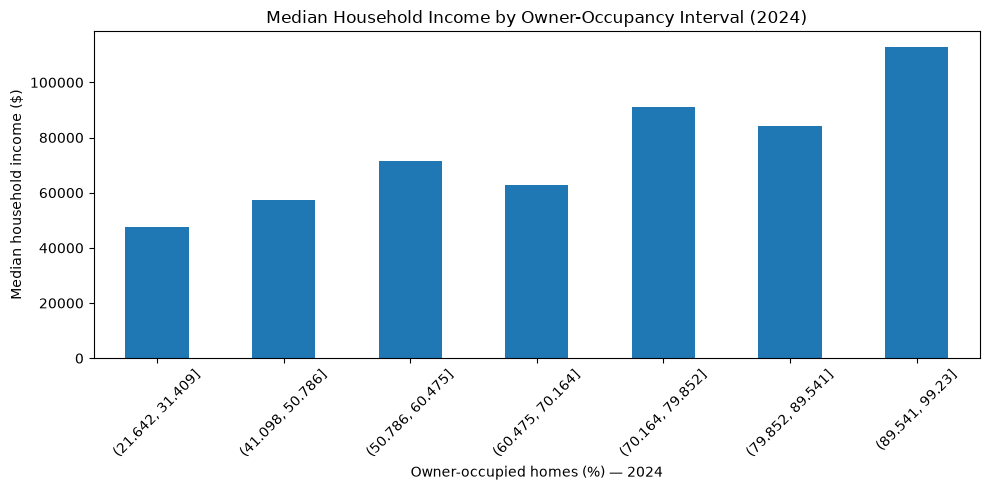

In [ ]:
owner_col = "pct_owner_occupied_2024"
income_col = "median_hh_income_2024"

plot_data = york[[owner_col, income_col]].dropna().copy()
plot_data["owner_interval"] = pd.cut(plot_data[owner_col], bins=8)

owner_income_summary = plot_data.groupby(
    "owner_interval", observed=True
)[income_col].agg(
    median_income="median",
    neighborhood_count="count"
)

display(owner_income_summary)

ax = owner_income_summary["median_income"].plot.bar(figsize=(10, 5))
ax.set_title("Median Household Income by Owner-Occupancy Interval (2024)")
ax.set_xlabel("Owner-occupied homes (%) — 2024")
ax.set_ylabel("Median household income ($)")
ax.tick_params(axis="x", labelrotation=45)
plt.tight_layout()
plt.show()